# 01 Wildfire: burn scar and recovery, Caldor Fire 2021

This notebook walks through the `wildfire` app of `tessera_apps` on its bundled demo, the Caldor Fire in the
Sierra Nevada, California. It is written for the dClimate builder community: people who can run Python and want
a working starting point.

The Caldor Fire ignited on 14 August 2021 and was contained on 21 October 2021, after burning about 221,835
acres (89,775 ha) in El Dorado, Amador and Alpine counties. Its east end crosses 120 W, so the area of interest
(AOI) touches two UTM zone groups of the store, 10N and 11N, and the app mosaics them.

Everything here runs on the TESSERA v1.1 annual embeddings: one 128-dimensional int8 vector per 10 m pixel per
year, read anonymously from the public Icechunk store. No GPU, no model training, no credentials.

## 1. What the app answers

**Where did it burn, and how far has each burned pixel recovered since?**

The method, in five steps:

1. **Change.** For every AOI pixel, the cosine distance between its embedding in `year_a` (2020, the year
   before the fire) and `year_b` (2022, the year after it). The 2021 embedding is an annual summary that only
   partly sees a fire that started in mid August, so the year after the fire is the cleaner "after" image.
   Pixels whose radar regime differs between the two years (Sentinel-1 present in one year and absent in the
   other) are not classified: that switch alone moves a pixel by 0.13 to 0.25 of cosine distance.
2. **Threshold.** Otsu's threshold on the histogram of AOI distances. When the histogram is not bimodal (no
   clear burn mode), the app falls back to the 99th percentile of the distance between two pre-fire years
   (2019 and 2020) and records that it did. `--threshold` overrides both.
3. **Clean.** A 3 x 3 morphological opening, then patches under `--min-area-ha` (default 1 ha) are dropped.
   This runs on the mosaic of both zones, so a patch crossing 120 W is judged whole.
4. **Recovery.** For each year from 2022 to 2025, each burned pixel's cosine similarity to its own 2020 vector,
   compared with land the app has shown to be unchanged (the recovery reference). A burned pixel counts as
   *recovered* when its similarity reaches the 10th percentile of the reference's in that year, and its
   recovery index `R_t = (s_t - s_post) / (s_ref_t - s_post)` measures how far it has moved from its post-fire
   state (`R = 0`) back towards unchanged land (`R = 1`).
5. **Validate.** Score the burned mask against a reference outline: IoU, precision, recall, F1, plus recall
   inside the reference and the share of the burned mask that falls outside it. Given a burn severity map
   (`--severity`), also per severity class: how much of each class the app calls burned, and the same scores
   against moderate or worse burn and against low or worse burn (section 9).

The outputs are a float32 Cloud Optimized GeoTIFF (distance, burned mask, one recovery index band per year), two
false colour COGs, a summary table (parquet and csv), a preview PNG, a validation JSON and a report JSON that
records provenance, timings and bytes read.

In [1]:
from __future__ import annotations

import json
import logging
from pathlib import Path

import geopandas as gpd
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.plot import plotting_extent
from rasterio.warp import reproject
from scipy import ndimage

import tessera_apps
from tessera_apps import export, io, validate
from tessera_apps.apps import load_aoi, run_wildfire, wildfire
from tessera_apps.cache import cache_dir
from tessera_apps.demo import demo_geojson, demo_properties
from tessera_apps.export import GridArray

# Show the app's own log lines (the run plan, "outputs are current", bytes read).
_handler = logging.StreamHandler()
_handler.setFormatter(logging.Formatter("%(levelname)s %(name)s: %(message)s"))
_log = logging.getLogger("tessera_apps")
_log.handlers[:] = [_handler]
_log.setLevel(logging.INFO)
_log.propagate = False

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72, "font.size": 10})
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

OUT = Path("out/wildfire")
REF = Path("out/hansen2021_outline.geojson")
# The Sentinel-2 dNBR burn severity proxy of section 9, built by scripts/make_caldor_dnbr.py.
SEVERITY = cache_dir() / "reference" / "s2_dnbr" / "caldor_s2_dnbr6.tif"
YEAR_A, YEAR_B = 2020, 2022
MAX_SIDE = 700  # longest side of every image shown here, in pixels
print("tessera_apps", tessera_apps.__version__)

tessera_apps 0.1.0.dev0


## 2. The validation reference

The brief asks for validation against the NIFC Wildland Fire Perimeter of Caldor. NIFC serves its perimeters
from `services3.arcgis.com`, which the environment this notebook was built in cannot reach (the proxy answers
403). So this notebook validates against the **Hansen Global Forest Change v1.13 2021 loss outline** that ships
with the Caldor demo: the filled outline of the 2021 stand-replacing loss patches that also defined the demo
AOI. It is a weaker reference than NIFC in two ways, both measured in section 8: a filled outline includes
unburned islands, and Hansen records stand-replacing forest loss, not burn severity.

The demo file carries the outline as a second feature. Write it to a GeoJSON and pass it as `reference=`, the
same way you would pass an EFFIS or a hand-drawn perimeter with `--reference`.

Section 9 adds a second kind of reference, a burn severity map, which says how severely each pixel burned
rather than only whether it lies inside an outline. MTBS, the US severity product, cannot be reached from the
build environment either, so a Sentinel-2 dNBR proxy built by `scripts/make_caldor_dnbr.py` stands in. It is
passed with `severity=` (`--severity`). Build it once before running this notebook:

```
python scripts/make_caldor_dnbr.py
```

It reads only the AOI windows of 32 Sentinel-2 products from the public archive on AWS (about 610 MB, two
minutes outside `us-west-2`, no credentials) and writes a 0.8 MB COG under `~/.cache/tessera_apps/`.

In [2]:
collection = demo_geojson("caldor")
outline = [f for f in collection["features"] if (f.get("properties") or {}).get("role") == "hansen_2021_loss_outline"]
REF.parent.mkdir(parents=True, exist_ok=True)
with REF.open("w", encoding="utf-8") as fh:
    json.dump({"type": "FeatureCollection", "features": outline}, fh)

aoi_props = demo_properties("caldor")
print("AOI:", aoi_props["name"])
print("AOI definition:", aoi_props["source"], f"({aoi_props['buffer_km']} km)")
print("AOI status:", aoi_props["status"])
print("Reference written to", REF, "sha256", export.file_sha256(REF)[:16])
if not SEVERITY.is_file():
    raise FileNotFoundError(
        f"The severity map {SEVERITY} is missing: build it first with `python scripts/make_caldor_dnbr.py` "
        "from the repository root (section 2)."
    )
print("Severity map", SEVERITY.name, "sha256", export.file_sha256(SEVERITY)[:16])

AOI: Caldor Fire 2021 demo AOI
AOI definition: Hansen GFC v1.13 lossyear == 21: largest connected patch plus patches of at least 500 ha within 1.0 km of it; bbox buffered (2.0 km)
AOI status: provisional: replace with the NIFC perimeter bbox plus 2 km when NIFC is reachable
Reference written to out/hansen2021_outline.geojson sha256 d096b2440cc311d3
Severity map caldor_s2_dnbr6.tif sha256 1ce333dee3236a4c


## 3. Run it

From a shell, the same run is one command (run after the call below, it finds the outputs current and skips):

```
tessera-apps wildfire --aoi caldor --year-a 2020 --year-b 2022 --out notebooks/out/wildfire \
    --validate --reference notebooks/out/hansen2021_outline.geojson \
    --severity ~/.cache/tessera_apps/reference/s2_dnbr/caldor_s2_dnbr6.tif
```

In Python it is one call. The full run reads every 2020, 2022, 2023, 2024 and 2025 chunk of a 279,849 ha AOI,
plus a sample of 2019 (about 23 GB in all, section 10). It is idempotent: when `out/wildfire` already holds
outputs that the report says were written with the same arguments, AOI, reference and severity files, code and
store snapshot, the call reads only the store's metadata and returns at once with `skipped` set. Delete `out/wildfire` or pass
`force=True` to recompute.

In [3]:
result = run_wildfire("caldor", YEAR_A, YEAR_B, OUT, validate=True, reference=REF, severity=SEVERITY)
report, summary = result.report, result.summary
print("skipped (outputs current):", result.skipped)
print("headline:", summary["headline"]["text"])
for path in [
    result.paths.tif,
    *result.extra_paths.values(),
    result.paths.summary_parquet,
    result.paths.summary_csv,
    result.paths.preview,
    result.paths.validation,
    result.paths.report,
]:
    print(f"  {path.name:28s} {path.stat().st_size / 1e6:8.2f} MB")

INFO tessera_apps.apps._common: wildfire: outputs in out/wildfire are current for these arguments; pass --force to rerun.


skipped (outputs current): True
headline: Severity (Sentinel-2 dNBR proxy): IoU 0.813 against moderate or worse; detected high 99.6%, moderate 77.5%, low 9.7%, unburned to low 0.3%, increased greenness 1.2%. Reference outline: recall inside it 0.677, IoU 0.645.
  wildfire_2020_2022.tif         278.34 MB
  wildfire_pca_2020.tif           89.31 MB
  wildfire_pca_2022.tif           86.16 MB
  wildfire_summary.parquet         0.01 MB
  wildfire_summary.csv             0.00 MB
  wildfire_preview.png             1.59 MB
  wildfire_validation.json         0.01 MB
  wildfire_report.json             0.01 MB


In [4]:
th = summary["threshold"]
pd.Series(
    {
        "AOI area (ha)": f"{summary['aoi_area_ha']:,.0f}",
        "zones": ", ".join(summary["zones"]),
        "classified pixels": f"{summary['classified_pixels']:,}",
        "radar regime mismatch 2020 vs 2022": f"{summary['radar']['radar_mismatch_fraction']:.2%}",
        "threshold (cosine distance)": f"{th['threshold']:.4f} ({th['method']})",
        "burned pixels before cleaning": f"{summary['burned_pixels_before_cleaning']:,}",
        "burned pixels after cleaning": f"{summary['burned_pixels']:,}",
        "burned area (ha)": f"{summary['burned_area_ha']:,.0f}",
        "burned fraction of classified pixels": f"{summary['burned_fraction']:.1%}",
        "official Caldor area (ha)": "89,775",
        "warnings": len(report["warnings"]),
    },
    name="Caldor 2020 to 2022",
).to_frame()

,Caldor 2020 to 2022
AOI area (ha),"279,849"
zones,"10N, 11N"
classified pixels,"27,984,594"
radar regime mismatch 2020 vs 2022,0.00%
threshold (cosine distance),0.2440 (otsu)
burned pixels before cleaning,"5,494,512"
burned pixels after cleaning,"5,144,264"
burned area (ha),"51,443"
burned fraction of classified pixels,18.4%
official Caldor area (ha),"89,775"


The app calls about 51,400 ha burned, 57% of the official 89,775 ha. That gap is expected and is the subject of
sections 8 and 9: the official figure is the area inside the final perimeter, unburned islands and lightly burned
understory included, while the mask counts only pixels whose embedding changed strongly.

## 4. PCA false colour, before and after

A false colour image of the embeddings: the first three principal components, mapped to red, green and blue.
The basis is fitted once, on a deterministic sample of about 200,000 pixels of 2020, and applied to both years,
so a colour means the same thing in both images. The burn scar is the area that turns from red and orange to violet across the
west and centre of the AOI. The images are read from the two PCA COGs at reduced resolution (the COG overviews make that cheap).

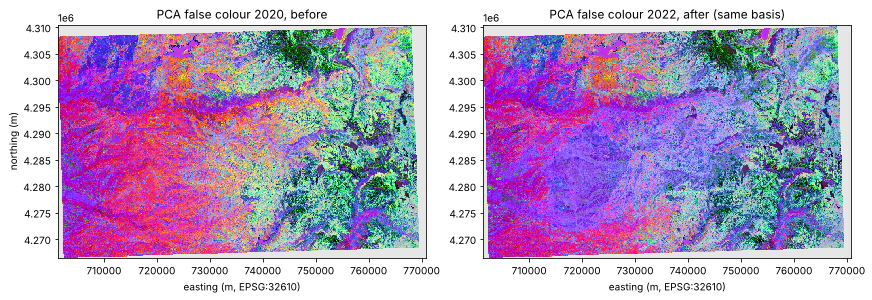

PCA basis: {'blocks_read': 32, 'blocks_total': 44, 'fit_year': 2020, 'pixels': 197039}


In [5]:
def read_small(path: Path, band: int | None = None, max_side: int = MAX_SIDE) -> tuple[np.ndarray, tuple, object]:
    """Read a COG (or one band) decimated to at most ``max_side`` pixels, with its plotting extent and CRS.

    GDAL serves a decimated read from the COG overviews where it can.
    """
    with rasterio.open(path) as ds:
        step = max(1, int(np.ceil(max(ds.width, ds.height) / max_side)))
        shape = (ds.height // step, ds.width // step)
        if band is None:
            data = ds.read(out_shape=(ds.count, *shape), resampling=Resampling.nearest)
        else:
            data = ds.read(band, out_shape=shape, resampling=Resampling.nearest)
        return data, plotting_extent(ds), ds.crs


pca_a, extent, crs = read_small(result.extra_paths["pca_a"])
pca_b, _, _ = read_small(result.extra_paths["pca_b"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
for ax, img, title in ((axes[0], pca_a, f"{YEAR_A}, before"), (axes[1], pca_b, f"{YEAR_B}, after (same basis)")):
    rgb = np.moveaxis(img, 0, -1)
    nodata = (rgb == 0).all(axis=-1)
    rgb = np.where(nodata[..., None], 230, rgb).astype(np.uint8)
    ax.imshow(rgb, extent=extent, interpolation="nearest")
    ax.set_title(f"PCA false colour {title}")
    ax.set_xlabel(f"easting (m, {crs})")
axes[0].set_ylabel("northing (m)")
plt.show()
print("PCA basis:", summary["pca"])

## 5. Distance map, threshold and the Otsu histogram

The first band of the output COG is the 2020 to 2022 cosine distance. Unchanged land sits near 0.04 (the median
of pixels outside both the mask and the reference outline): two annual embeddings of the same ground are never
identical. Burned forest sits far higher, around 0.4. Otsu's method picks the threshold that best separates the
two modes of the histogram; the app also checks that the histogram really has a valley between them
(`valley_ratio`: the floor of the smoothed histogram between the two peaks over the lower peak; at most 0.9
counts as bimodal) before trusting Otsu. Here both checks pass, so the stable-pair fallback did not run.

bands: ['distance_2020_2022', 'burned', 'recovery_index_2022', 'recovery_index_2023', 'recovery_index_2024', 'recovery_index_2025']


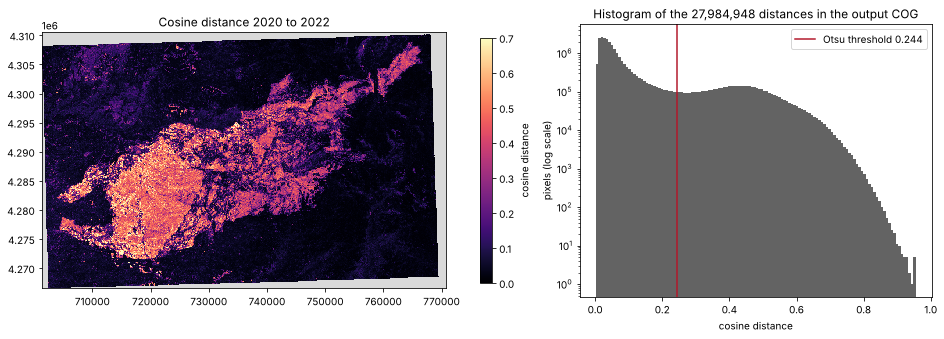

,threshold
threshold,0.244
method,otsu
Otsu threshold,0.244
"Otsu eta (separability, 0 to 1)",0.838
Otsu high mode share,0.196
valley ratio (at most 0.9 is bimodal),0.66
bimodal (both checks),True
fallback ran,False
distance p50 / p99,0.052 / 0.621


In [6]:
with rasterio.open(result.paths.tif) as ds:
    band_names = list(ds.descriptions)
    dist = ds.read(1)
    mosaic_transform, mosaic_crs, mosaic_extent = ds.transform, ds.crs, plotting_extent(ds)
print("bands:", band_names)
finite = dist[np.isfinite(dist)]
counts, edges = np.histogram(finite, bins=128)
otsu = th["otsu"] or {}
step = max(1, int(np.ceil(max(dist.shape) / MAX_SIDE)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained", gridspec_kw={"width_ratios": [1.15, 1]})
cmap = plt.get_cmap("magma").with_extremes(bad="#d9d9d9")
shown = axes[0].imshow(
    np.ma.masked_invalid(dist[::step, ::step]),
    cmap=cmap,
    vmin=0,
    vmax=0.7,
    extent=mosaic_extent,
    interpolation="nearest",
)
fig.colorbar(shown, ax=axes[0], label="cosine distance", shrink=0.9)
axes[0].set_title(f"Cosine distance {YEAR_A} to {YEAR_B}")
axes[1].stairs(counts, edges, fill=True, color="#636363")
axes[1].axvline(th["threshold"], color="#b2182b", label=f"Otsu threshold {th['threshold']:.3f}")
axes[1].set_yscale("log")
axes[1].set_xlabel("cosine distance")
axes[1].set_ylabel("pixels (log scale)")
axes[1].set_title(f"Histogram of the {finite.size:,} distances in the output COG")
axes[1].legend()
plt.show()

pd.Series(
    {
        "threshold": th["threshold"],
        "method": th["method"],
        "Otsu threshold": otsu.get("threshold"),
        "Otsu eta (separability, 0 to 1)": otsu.get("eta"),
        "Otsu high mode share": otsu.get("high_mode_share"),
        "valley ratio (at most 0.9 is bimodal)": th["valley_ratio"],
        "bimodal (both checks)": th["bimodal"],
        "fallback ran": th["fallback_ran"],
        "distance p50 / p99": f"{np.percentile(finite, 50):.3f} / {np.percentile(finite, 99):.3f}",
    },
    name="threshold",
).to_frame()

## 6. Burned mask over the reference outline

Band 2 of the COG is the burned mask (1 burned, 0 not burned, no data where a pixel was not classified). Below,
on the left, the mask with the Hansen 2021 loss outline drawn in blue; on the right, where the two agree and
disagree: burned inside the outline (dark red), burned outside it (orange), and outline pixels the app did not
call burned (blue).

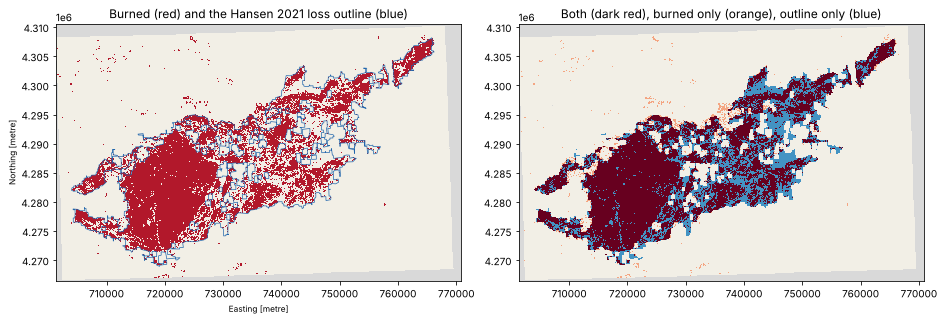

In [7]:
with rasterio.open(result.paths.tif) as ds:
    burned_band = ds.read(2)
outline_gdf = gpd.read_file(REF).to_crs(mosaic_crs)
# Pixel-centre rule, as the app's own reference rasterization.
outline_px = rasterize(
    ((g, 1) for g in outline_gdf.geometry),
    out_shape=burned_band.shape,
    transform=mosaic_transform,
    fill=0,
    dtype="uint8",
).astype(bool)
classified = np.isfinite(burned_band)
burned = burned_band == 1
agree = np.full(burned_band.shape, np.nan, dtype=np.float32)
agree[classified & ~burned & ~outline_px] = 0  # neither
agree[classified & burned & outline_px] = 1  # both
agree[classified & burned & ~outline_px] = 2  # burned outside the outline
agree[classified & ~burned & outline_px] = 3  # outline, not burned

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
burn_cmap = ListedColormap(["#f2efe6", "#b2182b"]).with_extremes(bad="#d9d9d9")
axes[0].imshow(
    np.ma.masked_invalid(burned_band[::step, ::step]),
    cmap=burn_cmap,
    vmin=0,
    vmax=1,
    extent=mosaic_extent,
    interpolation="nearest",
)
outline_gdf.boundary.plot(ax=axes[0], color="#2166ac", linewidth=0.7)
axes[0].set_xlim(mosaic_extent[:2])
axes[0].set_ylim(mosaic_extent[2:])
axes[0].set_title("Burned (red) and the Hansen 2021 loss outline (blue)")
agree_cmap = ListedColormap(["#f2efe6", "#67001f", "#f4a582", "#4393c3"]).with_extremes(bad="#d9d9d9")
axes[1].imshow(
    np.ma.masked_invalid(agree[::step, ::step]),
    cmap=agree_cmap,
    vmin=-0.5,
    vmax=3.5,
    extent=mosaic_extent,
    interpolation="nearest",
)
axes[1].set_title("Both (dark red), burned only (orange), outline only (blue)")
plt.show()

## 7. Recovery, 2022 to 2025

For each burned pixel and each year `t`, `s_t` is the cosine similarity of its year `t` embedding to its own 2020
embedding. The recovery reference is land the app has shown to be unchanged between 2020 and 2022 (distance at
most half the threshold, and more than 5 pixels from any burned pixel). The summary table has one row per year:

- `recovered_fraction`: share of burned pixels whose `s_t` reaches the 10th percentile of the reference's `s_t`
  that year (`unburned_sim_p10`), that is, back inside the range of unchanged land. This is the calibrated metric.
- `median_recovery_index`: median of `R_t = (s_t - s_post) / (s_ref_t - s_post)`, 0 at the post-fire state, 1 at
  the reference median (clipped to -1 to 2, undefined where the denominator is under 0.02).
- `sim90_fraction`: the brief's original metric, the share of burned pixels with `s_t` above 0.9.

In [8]:
table = pd.read_parquet(result.paths.summary_parquet)
shown = table.set_index("year")[
    [
        "n_burned",
        "median_sim_burned",
        "median_sim_unburned",
        "unburned_sim_p10",
        "recovered_fraction",
        "median_recovery_index",
        "sim90_fraction",
        "radar_mismatch_fraction",
    ]
].copy()
for col in ("recovered_fraction", "sim90_fraction", "radar_mismatch_fraction"):
    shown[col] = shown[col].map(lambda x: f"{x:.2%}")
shown["n_burned"] = shown["n_burned"].map(lambda x: f"{x:,}")
shown

,n_burned,median_sim_burned,median_sim_unburned,unburned_sim_p10,recovered_fraction,median_recovery_index,sim90_fraction,radar_mismatch_fraction
year,,,,,,,,
2022,"5,144,264",0.567,0.964,0.919,0.00%,0.000,0.00%,0.00%
2023,"5,144,264",0.598,0.958,0.907,0.03%,0.079,0.06%,0.00%
2024,"5,144,214",0.617,0.970,0.922,0.16%,0.127,0.53%,0.00%
2025,"5,144,232",0.599,0.960,0.895,0.74%,0.091,0.59%,0.00%


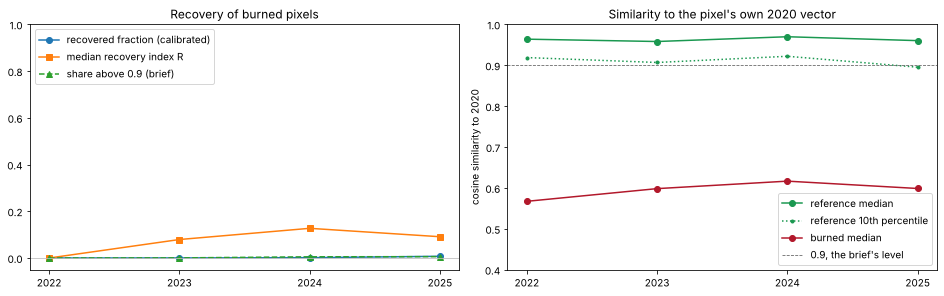

Recovery reference: 19,488,562 pixels, Classified pixels whose 2020 to 2022 distance is at most 0.5 x the threshold and that lie more than 5 pixels from any burned pixel.
  similarity 2019 to 2020 (a sample of 4 blocks): median 0.965, share above 0.9 97.2%
  similarity 2020 to 2022: median 0.964, share above 0.9 95.9%


Every classified pixel not called burned (22,840,669): median similarity 2020 to 2022 0.958, share above 0.9 83.5%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.0), layout="constrained")
ax = axes[0]
ax.plot(table["year"], table["recovered_fraction"], marker="o", label="recovered fraction (calibrated)")
ax.plot(table["year"], table["median_recovery_index"], marker="s", label="median recovery index R")
ax.plot(table["year"], table["sim90_fraction"], marker="^", linestyle="--", label="share above 0.9 (brief)")
ax.axhline(0, color="#bdbdbd", linewidth=0.8)
ax.set_ylim(-0.05, 1.0)
ax.set_xticks(table["year"])
ax.set_title("Recovery of burned pixels")
ax.legend(loc="upper left")
ax = axes[1]
ax.plot(table["year"], table["median_sim_unburned"], marker="o", color="#1a9850", label="reference median")
ax.plot(
    table["year"],
    table["unburned_sim_p10"],
    marker=".",
    color="#1a9850",
    linestyle=":",
    label="reference 10th percentile",
)
ax.plot(table["year"], table["median_sim_burned"], marker="o", color="#b2182b", label="burned median")
ax.axhline(0.9, color="#636363", linestyle="--", linewidth=0.8, label="0.9, the brief's level")
ax.set_xticks(table["year"])
ax.set_ylim(0.4, 1.0)
ax.set_ylabel(f"cosine similarity to {YEAR_A}")
ax.set_title(f"Similarity to the pixel's own {YEAR_A} vector")
ax.legend(loc="lower right")
plt.show()

ref = summary["recovery_reference"]
pre, post = ref["pre_fire_similarity"], ref["post_fire_similarity"]
print(f"Recovery reference: {ref['pixels']:,} pixels, {ref['definition']}")
print(
    f"  similarity {pre['years'][0]} to {pre['years'][1]} ({pre['coverage']}): median {pre['median']:.3f}, "
    f"share above 0.9 {pre['share_above_0_9']:.1%}"
)
print(
    f"  similarity {post['years'][0]} to {post['years'][1]}: median {post['median']:.3f}, "
    f"share above 0.9 {post['share_above_0_9']:.1%}"
)
not_burned = classified & ~burned
s_all = 1.0 - dist[not_burned]
print(
    f"Every classified pixel not called burned ({not_burned.sum():,}): median similarity {YEAR_A} to {YEAR_B} "
    f"{np.median(s_all):.3f}, share above 0.9 {np.mean(s_all > 0.9):.1%}"
)

**Why the brief's 0.9 metric stays near zero, and what that does and does not mean.** The brief proposed counting
a burned pixel as recovered when its similarity to its pre-fire vector exceeds 0.9. At Caldor that share stays
under 1% through 2025, and so does the calibrated `recovered_fraction`. The two agree here for a plain reason:
burned pixels sit at a median similarity of about 0.57 to 0.62 to their 2020 vector in every year from 2022 to
2025, far below either level. A conifer forest that burned at high severity does not come back in four years:
what grows first is shrubs and seedlings, a different land cover, and the embedding says so.

The planning notes for this checkpoint expected a second reason, that land which did not burn is itself only about
0.9 similar to itself after two years, so that a fixed 0.9 would fail half of stable land. That came from the 64 x
64 test window and from blocks inside the scar, and it does **not** hold for the whole AOI: the land the app
shows unchanged is about 0.96 similar to its 2020 vector in every year from 2022 to 2025, before the fire it was
also 0.965 similar from 2019 to 2020 (on a sample of blocks), and its 10th percentile sits between 0.895 and 0.922, close to 0.9. So at
Caldor the brief's fixed level happens to match the calibrated one. Where unchanged land drifts more (a radar
regime switch, snow years, farmland, or a small AOI mostly inside the scar), a fixed 0.9 would call stable land
unrecovered, and the calibrated metrics adapt because they are measured against that year's reference.

The recovery index is the more informative number while recovery is partial: the median burned pixel has moved
about a tenth of the way back to unchanged land by 2025 (`R` peaks at 0.13 in 2024), and the map below shows
where recovery is furthest along.

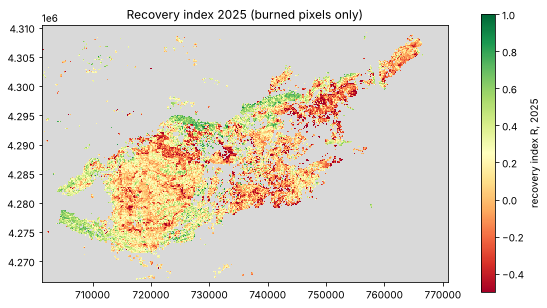

R 2025 on this decimated view: median 0.10, p90 0.49, share at least 0.5 9.7%


In [10]:
last = int(table["year"].max())
rec, _, _ = read_small(result.paths.tif, band=band_names.index(f"recovery_index_{last}") + 1)
fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
shown = ax.imshow(
    np.ma.masked_invalid(rec),
    cmap=plt.get_cmap("RdYlGn").with_extremes(bad="#d9d9d9"),
    vmin=-0.5,
    vmax=1.0,
    extent=mosaic_extent,
    interpolation="nearest",
)
fig.colorbar(shown, ax=ax, label=f"recovery index R, {last}", shrink=0.9)
ax.set_title(f"Recovery index {last} (burned pixels only)")
plt.show()
r_last = rec[np.isfinite(rec)]
print(
    f"R {last} on this decimated view: median {np.median(r_last):.2f}, p90 {np.percentile(r_last, 90):.2f}, "
    f"share at least 0.5 {np.mean(r_last >= 0.5):.1%}"
)

## 8. Validation numbers and caveats

The scores below come from `wildfire_validation.json`, computed by the app over every classified AOI pixel in
both zones (pixels valid in both years with the same radar regime), on each zone's own grid. This section reads
the scores against the outline; the severity block of the same file is section 9.

In [11]:
val_doc = json.loads(result.paths.validation.read_text(encoding="utf-8"))
v = summary["validation"]
rule = v["stop_rule"]
basis = "the severity map, moderate or worse (section 9)" if rule["basis"] == "severity" else "this outline"
pd.Series(
    {
        "reference": f"{val_doc['reference'].get('file')} ({v['source']})",
        "IoU": v["iou"],
        "precision": v["precision"],
        "recall": v["recall"],
        "F1": v["f1"],
        "recall inside reference": v["recall_inside_reference"],
        "burned outside reference (share of burned)": v["burned_outside_reference_fraction"],
        "pixels scored": f"{v['pixels_scored']:,}",
        "IoU below 0.6": v["iou_below_0_6"],
        "the stop-and-report rule (brief section 8) reads": f"{basis}: IoU {rule['iou']:.3f}",
        "stop-and-report rule triggered": rule["below_0_6"],
    },
    name="validation",
).to_frame()

,validation
reference,hansen2021_outline.geojson (file)
IoU,0.645
precision,0.933
recall,0.677
F1,0.784
recall inside reference,0.677
burned outside reference (share of burned),0.067
pixels scored,"27,984,594"
IoU below 0.6,False
the stop-and-report rule (brief section 8) reads,"the severity map, moderate or worse (section 9): IoU 0.813"


In [12]:
# The outline's caveats; the severity map's start with the threshold caveat and are printed in section 9.
caveats = val_doc["caveats"]
first_severity = caveats.index(wildfire.SEVERITY_THRESHOLD_CAVEAT)
for caveat in caveats[:first_severity]:
    print("-", caveat)

- Scores count AOI pixels valid in both years with the same radar regime, in every zone the AOI touches; pixels outside the AOI are never classified, so the AOI should extend past the scar.
- A filled outline or perimeter reference includes unburned islands, so a pixel-level burned mask has an IoU ceiling below 1 against it.
- Reference: the file hansen2021_outline.geojson (sha256 d096b2440cc311d3a3a64b8c12a7db236ef13bac17f3fa46345db5cfb09f2176), supplied with --reference.
- This reference appears to be derived from Hansen Global Forest Change loss, which records stand-replacing forest loss, not burn severity: low-severity burn and burned non-forest are not in it, and Hansen is itself a 30 m model.


### Where the disagreement is

An IoU on its own does not say what went wrong. The cell below splits the disagreement into its parts, on the
output mosaic's grid:

- **Outline pixels the app did not call burned.** Are they unchanged land (distance at most half the threshold:
  an unburned island, or ground the fire passed over without changing it) or real change below the threshold?
- **Hansen loss inside the outline.** The outline is filled; Hansen's own 2021 loss pixels cover only part of it.
  How much of the outline is stand-replacing loss, how much of that the app found, and how much of what the app
  found inside the outline is *not* Hansen loss (burn that Hansen does not record).
- **Edges.** How much of each kind of disagreement lies within 100 m of the outline's edge, where a 30 m reference
  outline and a 10 m mask disagree by construction.

This reads only the store's metadata (to build the zone grids) and the Hansen `lossyear` tiles from the public
Google Cloud bucket (windows, cached under `~/.cache/tessera_apps/`). The counts are on the mosaic grid, so they
can differ from the app's per-zone scores in the last digit.

In [13]:
plan = io.plan_aoi(io.TesseraReader.open(), load_aoi("caldor").geometry)
dst = max(plan.zones, key=lambda z: z.n_pixels).zone
hansen = {}
for year in (2021, 2022):
    loss, loss_t, _ = export.mosaic_zones(
        [GridArray(validate.hansen_loss(z, year - 1, year), z) for z in plan.zones],
        dst_zone=dst,
        nodata=export.BOOL_NODATA,
    )
    assert loss.shape == burned_band.shape and loss_t == mosaic_transform
    hansen[year] = (loss == 1) & classified

ref_px = outline_px & classified
edge_m = 10.0 * np.where(
    outline_px, ndimage.distance_transform_edt(outline_px), ndimage.distance_transform_edt(~outline_px)
)
tp, fp, fn = burned & ref_px, burned & ~ref_px, ref_px & ~burned
n = {k: int(a.sum()) for k, a in {"burned": burned, "outline": ref_px, "tp": tp, "fp": fp, "fn": fn}.items()}
h21 = hansen[2021]
rows = [
    ("IoU (mosaic grid)", n["tp"] / (n["burned"] + n["outline"] - n["tp"]), "the app's per-zone IoU is above"),
    ("outline, share of classified AOI pixels", n["outline"] / int(classified.sum()), ""),
    ("burned, share of classified AOI pixels", n["burned"] / int(classified.sum()), ""),
    ("MISSED: outline pixels not burned, share of outline", n["fn"] / n["outline"], "1 - recall"),
    (
        "  of which unchanged (distance at most threshold / 2)",
        (fn & (dist <= th["threshold"] / 2)).sum() / n["fn"],
        "unburned islands",
    ),
    (
        "  of which changed, but below the threshold",
        (fn & (dist > th["threshold"] / 2) & (dist <= th["threshold"])).sum() / n["fn"],
        "low severity burn",
    ),
    (
        "  of which above the threshold, removed by the cleaning",
        (fn & (dist > th["threshold"])).sum() / n["fn"],
        "opening and 1 ha minimum",
    ),
    ("  of which within 100 m of the outline edge", (fn & (edge_m <= 100)).sum() / n["fn"], "edges"),
    ("  of which Hansen 2021 loss", (fn & h21).sum() / n["fn"], "real loss the app missed"),
    ("  median distance of the missed pixels", float(np.median(dist[fn])), f"threshold {th['threshold']:.3f}"),
    (
        "outline called burned, outer 100 m of the outline",
        (tp & (edge_m <= 100)).sum() / (ref_px & (edge_m <= 100)).sum(),
        "",
    ),
    (
        "outline called burned, more than 1 km inside it",
        (tp & (edge_m > 1000)).sum() / (ref_px & (edge_m > 1000)).sum(),
        "",
    ),
    ("Hansen 2021 loss, share of the outline", (h21 & ref_px).sum() / n["outline"], "the outline is filled"),
    ("Hansen 2021 loss found burned (recall on loss pixels)", (h21 & burned).sum() / h21.sum(), ""),
    ("burned inside the outline that is not Hansen loss", (tp & ~h21).sum() / n["tp"], "burn Hansen does not record"),
    ("EXTRA: burned outside the outline, share of burned", n["fp"] / n["burned"], "1 - precision"),
    ("  of which within 100 m of the outline edge", (fp & (edge_m <= 100)).sum() / n["fp"], "edges"),
    ("  of which within 300 m of the outline edge", (fp & (edge_m <= 300)).sum() / n["fp"], ""),
    ("  of which Hansen 2022 loss", (fp & hansen[2022]).sum() / n["fp"], "later loss (salvage, delayed mortality)"),
    ("  of which Hansen 2021 loss", (fp & h21).sum() / n["fp"], "loss patches left out of the outline"),
]
diag = pd.DataFrame(rows, columns=["quantity", "value", "reading"]).set_index("quantity")
diag["value"] = diag["value"].map(lambda x: f"{x:.3f}")
diag

,value,reading
quantity,,
IoU (mosaic grid),0.645,the app's per-zone IoU is above
"outline, share of classified AOI pixels",0.253,
"burned, share of classified AOI pixels",0.184,
"MISSED: outline pixels not burned, share of outline",0.323,1 - recall
of which unchanged (distance at most threshold / 2),0.435,unburned islands
"of which changed, but below the threshold",0.483,low severity burn
"of which above the threshold, removed by the cleaning",0.083,opening and 1 ha minimum
of which within 100 m of the outline edge,0.166,edges
of which Hansen 2021 loss,0.069,real loss the app missed


**Reading it.** Against the Hansen outline the IoU is 0.645, and it was not tuned: the threshold is Otsu's, every
parameter is the default, and the reference was fixed before the run. It is above 0.6, but it is no longer the
number the brief's stop-and-report rule reads: with a severity map given, the rule reads the IoU against moderate
or worse burn instead (0.813, section 9), since an outline counts unburned islands as burned.
The score is limited by recall (0.68), not precision (0.93):

- **Most of the disagreement is outline pixels the app did not call burned**, about 2.3 million pixels against
  0.35 million burned pixels outside the outline. Roughly 43% of those missed pixels are unchanged land (distance
  at most half the threshold; land outside both the mask and the outline has a median distance of 0.04): unburned
  islands, or ground where the fire left no lasting change, which a filled outline counts as burned. Another
  48% did change, with distances between 0.12 and the 0.244 threshold: that is the signature of low to moderate
  severity burn, where the canopy survived (section 9 confirms it). The last 8% are above the threshold but were
  removed by the cleaning (the 3 x 3 opening and the 1 ha minimum). Only about 7% of the missed pixels are Hansen 2021 loss pixels, and the
  app finds 95% of Hansen's own loss pixels.
- **The outline is only half stand-replacing loss.** Hansen 2021 loss covers about 51% of the outline's pixels;
  the rest is the fill between loss patches. Conversely, 28% of what the app calls burned inside the outline is
  not Hansen loss: burn that changed the land without removing the stand, which Hansen does not record.
- **Edges matter, but less than islands.** About 17% of the missed pixels and 39% of the extra pixels lie within
  100 m of the outline's edge, where the 30 m outline and the 10 m mask disagree by construction. The share of
  the outline called burned rises from about 43% in its outer 100 m to about 83% more than 1 km inside it.
- **The extra pixels are mostly real change.** Half of the burned pixels outside the outline are Hansen 2022 loss
  (most likely delayed tree mortality and post-fire salvage logging: inside the 2020 to 2022 window, but outside a
  2021-only outline), and another 13% are 2021 loss patches the outline left out.

So the IoU measures the reference as much as the method. A pixel mask scored against any filled outline has a
ceiling well below 1, and the low-severity part of the fire is a real limit of a single distance threshold, not
something to tune away against this reference: the same distance band (0.12 to 0.24) holds about 1.3 million
pixels outside the outline, more than the 1.1 million missed inside it, so moving the threshold would trade one
disagreement for another. Section 9 scores the mask against a burn severity map and splits this disagreement by
severity class:
three quarters of the missed outline pixels are low (49%) or unburned to low (26%) severity, and so are four fifths
of those 1.3 million changed pixels outside it (33% low, 46% unburned to low). Lowering the threshold would add
low-severity burn inside and outside the outline alike. In the other direction, 77% of the burned pixels outside the
outline are moderate or high burn that the outline leaves out.

### NIFC, where it is reachable

The brief's checkpoint asks for the IoU against the NIFC Caldor perimeter. That number must be computed where
`services3.arcgis.com` is reachable. Without `--reference`, `--validate` fetches the NIFC perimeter itself, so it is
one command (a new output directory, because a different reference is a different run):

```
tessera-apps wildfire --aoi caldor --year-a 2020 --year-b 2022 --validate --fire-name Caldor --out out/wildfire_nifc
```

From the build environment that run still completes and writes every other output, but no
`wildfire_validation.json`; it records the failure in the report's warnings and prints it (add `--strict-validate`
to stop with exit code 3 instead, before any chunk is read). The warning, as the report records it:

> Validation skipped, the reference could not be loaded: Could not reach services3.arcgis.com for NIFC (Tunnel connection failed: 403 Forbidden). Download the perimeter by hand (for example from the NIFC open data site, https://data-nifc.opendata.arcgis.com) and pass it with --reference path.geojson (reference_from_file).

What to expect: IoU is at most the smaller area over the larger, and the mask (about 51,400 ha) is 57% of the
official 89,775 ha, so the NIFC IoU cannot exceed about 0.57 if the whole perimeter lies inside the AOI. It will
very likely land below 0.6 for the reasons measured above and in section 9 (the perimeter is an outer boundary
that includes unburned islands and low-severity burn). Report it with recall inside the perimeter first, as the
headline does, and do not tune it. Add `--severity` to the same command to score both references in one run:
the brief's stop-and-report rule then reads the severity IoU against moderate or worse, and the severity scores
are written even when NIFC cannot be reached (a later rerun retries NIFC from the outputs on disk, without
reading the store).

## 9. Scored against burn severity

An outline only says inside or outside the fire. The brief's NIFC perimeter is the outer boundary of the fire:
unburned islands and lightly burned understory inside it count as burned, so a mask that maps the fire well still
scores a low IoU against it (section 8 measured the same effect on the filled Hansen outline).
The owner's decision for checkpoint 3 was to score the wildfire app against a **burn severity map** as well, in the
style of MTBS (Monitoring Trends in Burn Severity): how much of each severity class the app calls burned, and the
IoU against moderate or worse burn, which is also what the brief's stop-and-report rule reads once a severity map is
given.

MTBS cannot be reached from the environment this notebook was built in (`mtbs.gov` and its data server are blocked
at the proxy), so a **Sentinel-2 dNBR proxy** stands in, built by `scripts/make_caldor_dnbr.py` from the public
Sentinel-2 L2A COG archive on AWS (AOI windows only, read anonymously):

- **NBR** = (B8A - B12) / (B8A + B12) on clear pixels (scene classification: vegetation or not vegetated), the
  per-pixel median over 8 dates before the fire (15 June to 9 August 2021; ignition was 14 August) and over 8 dates
  one year on (15 June to 27 August 2022, the timing of an MTBS extended assessment, and before the Mosquito Fire of
  September 2022 to the north).
- **dNBR** = NBR before minus NBR after, minus its median over land taken as unburned (AOI pixels more than 2 km
  outside the Hansen outline), as MTBS offsets dNBR.
- **Classes** of 1000 x dNBR on the generic Key and Benson thresholds, in MTBS dnbr6 codes: 1 unburned to low (under
  100), 2 low (100 to 269), 3 moderate (270 to 659), 4 high (660 and above), 5 increased greenness (under -100),
  6 non-processing (no clear observation in a period; water falls here).

Its caveats, before any number: MTBS sets its class thresholds per fire by analyst judgement and these are generic;
the classes are 20 m pixels against the 10 m mask; and the proxy is **not independent** of the app. TESSERA's
embeddings are themselves learned from Sentinel-2 (and Sentinel-1) time series, and the post-fire composite falls
inside 2022, the app's `year_b`. The proxy's offset region also leans on the Hansen outline. The file carries the tag
`TESSERA_APPS_SOURCE=sentinel2_dnbr`, so the app labels it the Sentinel-2 proxy, not MTBS, in the headline, the
caveats and the CLI. Below, the proxy's own record first (from the JSON written next to the COG).

In [14]:
sev_info = val_doc["reference"]["severity"]
side = json.loads(SEVERITY.with_suffix(".json").read_text(encoding="utf-8"))
print(
    f"{sev_info['file']}: sha256 {sev_info['sha256'][:16]}, {sev_info['crs']} at {sev_info['resolution'][0]:g} m, "
    f"source tag {sev_info['source_tag']} (proxy: {sev_info['proxy']})"
)
n_products = sum(len(side["scenes"][p]) for p in ("pre", "post"))
print(
    f"tiles {', '.join(side['tiles'])}: {n_products} products, {side['bytes_read'] / 1e6:.0f} MB of COG blocks read "
    f"in {side['seconds']:.0f} s"
)
for period, label in (("pre", "before the fire"), ("post", "one year on")):
    dates = sorted({s["date"] for s in side["scenes"][period]})
    print(f"  {label}: {len(dates)} dates, {dates[0]} to {dates[-1]}")
print(
    f"dNBR offset {side['dnbr_offset']:+.4f}: the median dNBR of {side['offset_region_pixels']:,} pixels "
    "taken as unburned"
)
areas, in_outline = side["sanity"]["class_areas_aoi"], side["sanity"]["hansen_outline_by_class"]
pd.DataFrame(
    {
        f"{c} {wildfire.SEVERITY_NAMES[int(c)]}": {
            "hectares in the AOI": f"{a['hectares']:,.0f}",
            "share of the AOI": f"{a['share']:.1%}",
            "share of the Hansen outline": f"{in_outline[c]['share']:.1%}",
        }
        for c, a in areas.items()
        if a["pixels"]
    }
).T

caldor_s2_dnbr6.tif: sha256 1ce333dee3236a4c, EPSG:32610 at 20 m, source tag sentinel2_dnbr (proxy: True)
tiles 10SGH, 10SGJ: 32 products, 612 MB of COG blocks read in 119 s
  before the fire: 8 dates, 2021-06-15 to 2021-08-09
  one year on: 8 dates, 2022-06-15 to 2022-08-27
dNBR offset -0.0133: the median dNBR of 3,625,226 pixels taken as unburned


,hectares in the AOI,share of the AOI,share of the Hansen outline
1 unburned to low,"192,441",68.8%,8.7%
2 low,"25,110",9.0%,18.8%
3 moderate,"35,793",12.8%,43.3%
4 high,"20,746",7.4%,28.9%
5 increased greenness,"2,270",0.8%,0.3%
6 non-processing,"3,491",1.2%,0.0%


### Detection per severity class

The app's own scores, from the `severity` block of `wildfire_validation.json`: for each class, the share of its
classified pixels the app called burned (the detection rate), and where the app's burned pixels fall. Non-processing
pixels (class 6) and pixels the map does not cover are left out of every score and counted. The last column, the
median 2020 to 2022 cosine distance of the class, is computed here on the output mosaic's grid, with the severity map
read onto it by nearest resampling, as the app reads it onto each zone's grid.

In [15]:
sev = val_doc["scores"]["severity"]
sv = v["severity"]
sev_px = np.full(burned_band.shape, wildfire.SEVERITY_UNMAPPED, dtype=np.uint8)
with rasterio.open(SEVERITY) as ds:
    reproject(
        rasterio.band(ds, 1),
        sev_px,
        dst_transform=mosaic_transform,
        dst_crs=mosaic_crs,
        dst_nodata=wildfire.SEVERITY_UNMAPPED,
        resampling=Resampling.nearest,
    )
where = sev["detections_by_class"]
rows = {}
for c in (*wildfire.SEVERITY_HEADLINE_ORDER, wildfire.SEVERITY_BACKGROUND):
    row = sev["classes"][str(c)]
    if not row["pixels"]:
        continue  # the proxy maps no background: pixels outside the AOI are its nodata
    rows[f"{c} {row['name']}"] = {
        "hectares": f"{row['hectares']:,.0f}",
        "called burned (ha)": f"{row['detected_hectares']:,.0f}",
        "detection rate": f"{row['detection_rate']:.1%}",
        "share of the app's burned": f"{where[str(c)]['share']:.1%}",
        "median distance": f"{np.median(dist[classified & (sev_px == c)]):.3f}",
    }
excluded = {
    "6 non-processing (excluded)": (
        sev["excluded"]["non_processing_pixels"],
        "6",
        sev_px == wildfire.SEVERITY_NON_PROCESSING,
    ),
    "outside the map (excluded)": (
        sev["excluded"]["unmapped_pixels"],
        "unmapped",
        sev_px == wildfire.SEVERITY_UNMAPPED,
    ),
}
for label, (n_px, key, px) in excluded.items():
    rows[label] = {
        "hectares": f"{n_px * 0.01:,.0f}",
        "called burned (ha)": f"{where[key]['pixels'] * 0.01:,.0f}",
        "detection rate": f"{where[key]['pixels'] / n_px:.1%}" if n_px else "",
        "share of the app's burned": f"{where[key]['share']:.1%}",
        "median distance": f"{np.median(dist[classified & px]):.3f}" if (classified & px).any() else "",
    }
pd.DataFrame(rows).T

,hectares,called burned (ha),detection rate,share of the app's burned,median distance
4 high,"20,747","20,673",99.6%,40.2%,0.481
3 moderate,"35,792","27,741",77.5%,53.9%,0.364
2 low,"25,109","2,436",9.7%,4.7%,0.131
1 unburned to low,"192,385",512,0.3%,1.0%,0.037
5 increased greenness,"2,270",28,1.2%,0.1%,0.110
6 non-processing (excluded),"3,489",52,1.5%,0.1%,0.029
outside the map (excluded),54,1,1.1%,0.0%,0.037


In [16]:
def score_row(block: dict) -> dict:
    """One row of binary scores from validation.json."""
    return {
        "IoU": f"{block['iou']:.3f}",
        "precision": f"{block['precision']:.3f}",
        "recall": f"{block['recall']:.3f}",
        "F1": f"{block['f1']:.3f}",
        "pixels scored": f"{block['n']:,}",
    }


scores_table = pd.DataFrame(
    {
        "moderate or worse (classes 3 and 4)": score_row(sev["moderate_or_worse"]),
        "low or worse (classes 2 to 4)": score_row(sev["low_or_worse"]),
        "Hansen 2021 loss outline (section 8)": score_row(val_doc["scores"]["burned"]),
    }
).T
zone_iou = {z: s["iou"] for z, s in sev["per_zone"]["moderate_or_worse"].items()}
print("IoU against moderate or worse per zone:", ", ".join(f"{z} {iou:.3f}" for z, iou in zone_iou.items()))
print(
    f"Stop-and-report rule: reads the {rule['basis']} IoU against class {rule['min_class']} "
    f"({wildfire.SEVERITY_NAMES[rule['min_class']]}) or worse, {rule['iou']:.3f}; below 0.6: {rule['below_0_6']}"
)
print(
    "Recovery reference (land the app takes as unchanged) in the proxy's moderate or high classes: "
    f"{sv['recovery_reference_burned_fraction']:.2%}"
)
scores_table

IoU against moderate or worse per zone: 10N 0.813, 11N 0.832
Stop-and-report rule: reads the severity IoU against class 3 (moderate) or worse, 0.813; below 0.6: False
Recovery reference (land the app takes as unchanged) in the proxy's moderate or high classes: 0.18%


,IoU,precision,recall,F1,pixels scored
moderate or worse (classes 3 and 4),0.813,0.942,0.856,0.897,"27,630,304"
low or worse (classes 2 to 4),0.619,0.989,0.623,0.764,"27,630,304"
Hansen 2021 loss outline (section 8),0.645,0.933,0.677,0.784,"27,984,594"


### The severity map and the burned mask

Left: the proxy's classes, with the outline of the app's burned mask in white (drawn where at least half of each
display cell of about 100 m is burned). Right: the distribution of the 2020 to 2022 cosine distance in each class,
with the Otsu threshold the app used.

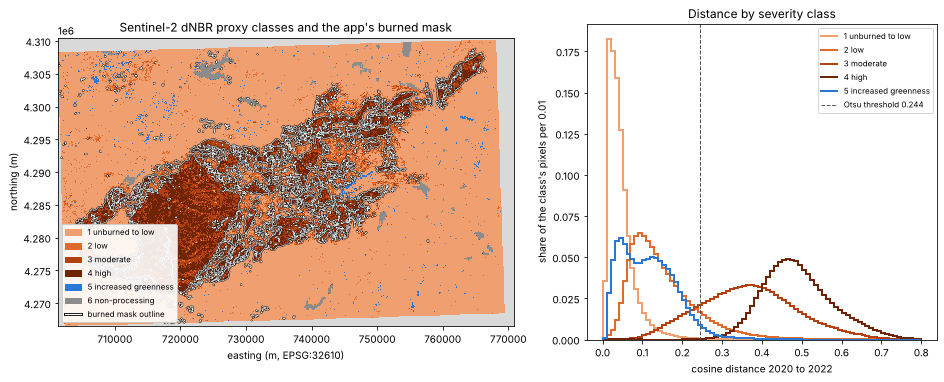

In [17]:
SEV_COLORS = {1: "#f0a070", 2: "#e06a2c", 3: "#b5400f", 4: "#6e2405", 5: "#2a78d6", 6: "#8c8c8c"}
k = step  # the decimation of section 5: about MAX_SIDE display cells on the long side
h, w = (dist.shape[0] // k) * k, (dist.shape[1] // k) * k
left, top = mosaic_transform.c, mosaic_transform.f
crop_extent = (left, left + w * mosaic_transform.a, top + h * mosaic_transform.e, top)
sev_small = sev_px[k // 2 : h : k, k // 2 : w : k]
burned_share = burned[:h, :w].reshape(h // k, k, w // k, k).mean(axis=(1, 3))
shown = np.ma.masked_where(
    ~np.isin(sev_small, list(SEV_COLORS)) | ~classified[k // 2 : h : k, k // 2 : w : k], sev_small
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), layout="constrained", gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
sev_cmap = ListedColormap([SEV_COLORS[c] for c in range(1, 7)]).with_extremes(bad="#d9d9d9")
ax.imshow(shown, cmap=sev_cmap, vmin=0.5, vmax=6.5, extent=crop_extent, interpolation="nearest")
# A white line with a dark halo reads on the light and the dark classes alike.
halo = [pe.withStroke(linewidth=1.6, foreground="#0b0b0b")]
outline_lines = ax.contour(
    burned_share, levels=[0.5], colors="#ffffff", linewidths=0.6, extent=crop_extent, origin="upper"
)
outline_lines.set_path_effects(halo)
handles = [Patch(color=SEV_COLORS[c], label=f"{c} {wildfire.SEVERITY_NAMES[c]}") for c in SEV_COLORS]
handles.append(
    Line2D(
        [],
        [],
        color="#ffffff",
        linewidth=1.2,
        path_effects=[pe.withStroke(linewidth=3, foreground="#0b0b0b")],
        label="burned mask outline",
    )
)
ax.legend(handles=handles, loc="lower left", fontsize=8, framealpha=0.9)
ax.set_title("Sentinel-2 dNBR proxy classes and the app's burned mask")
ax.set_xlabel(f"easting (m, {mosaic_crs})")
ax.set_ylabel("northing (m)")
ax = axes[1]
bins = np.linspace(0, 0.8, 81)
for c in (1, 2, 3, 4, 5):
    d = dist[classified & (sev_px == c)]
    hist, _ = np.histogram(d, bins=bins)
    ax.stairs(hist / d.size, bins, color=SEV_COLORS[c], linewidth=2, label=f"{c} {wildfire.SEVERITY_NAMES[c]}")
ax.axvline(th["threshold"], color="#52514e", linestyle="--", linewidth=1, label=f"Otsu threshold {th['threshold']:.3f}")
ax.set_xlabel(f"cosine distance {YEAR_A} to {YEAR_B}")
ax.set_ylabel("share of the class's pixels per 0.01")
ax.set_title("Distance by severity class")
ax.legend(fontsize=8)
plt.show()

### The outline disagreement, by severity class

Section 8 split the disagreement with the Hansen outline into missed and extra pixels. The proxy says what those
pixels are. Each column below is one set of pixels from section 8, split by severity class (each column sums to 1):
the outline itself, the outline pixels the app did not call burned, the land outside the outline that changed but
stayed under the threshold (distance between half the threshold and the threshold), and the burned pixels outside
the outline.

In [18]:
groups = {
    "1 unburned to low": sev_px == 1,
    "2 low": sev_px == 2,
    "3 moderate": sev_px == 3,
    "4 high": sev_px == 4,
    "5 increased greenness": sev_px == 5,
    "6 non-processing or outside the map": np.isin(
        sev_px, (wildfire.SEVERITY_NON_PROCESSING, wildfire.SEVERITY_UNMAPPED)
    ),
}
changed_below = classified & ~burned & (dist > th["threshold"] / 2) & (dist <= th["threshold"])
sets = {
    "outline": ref_px,
    "MISSED: outline, not burned": fn,
    "changed below the threshold, outside the outline": changed_below & ~outline_px,
    "EXTRA: burned outside the outline": fp,
}
split = pd.DataFrame(
    {name: {g: f"{(s & m).sum() / s.sum():.1%}" for g, m in groups.items()} for name, s in sets.items()}
)
split.loc["pixels"] = [f"{int(s.sum()):,}" for s in sets.values()]
low_hits = burned & np.isin(sev_px, (1, 2, 5))
print(
    f"Burned pixels in classes 1, 2 or 5: {low_hits.sum():,} ({low_hits.sum() / burned.sum():.1%} of the burned "
    f"mask); {(low_hits & hansen[2022]).sum() / low_hits.sum():.1%} of them are Hansen 2022 loss"
)
missed_moderate = classified & ~burned & (sev_px == 3)
print(
    f"Moderate pixels the app did not call burned: {missed_moderate.sum():,}, median distance "
    f"{np.median(dist[missed_moderate]):.3f} (threshold {th['threshold']:.3f})"
)
split

Burned pixels in classes 1, 2 or 5: 297,569 (5.8% of the burned mask); 15.8% of them are Hansen 2022 loss
Moderate pixels the app did not call burned: 805,149, median distance 0.216 (threshold 0.244)


,outline,"MISSED: outline, not burned","changed below the threshold, outside the outline",EXTRA: burned outside the outline
1 unburned to low,8.7%,26.2%,46.2%,9.4%
2 low,18.8%,49.2%,33.4%,11.5%
3 moderate,43.3%,23.5%,12.0%,70.5%
4 high,28.9%,0.2%,0.1%,6.6%
5 increased greenness,0.3%,0.9%,5.9%,0.6%
6 non-processing or outside the map,0.0%,0.0%,2.4%,1.5%
pixels,"7,088,641","2,290,753","1,332,478","346,391"


In [19]:
for caveat in caveats[first_severity:]:
    print("-", caveat)

- MTBS sets its dNBR class thresholds per fire, by analyst judgement; a dNBR proxy with generic thresholds is cruder, so the severity class boundaries are approximate.
- The severity classes are 30 m (MTBS) or 20 m (Sentinel-2) pixels read onto the 10 m grid by nearest resampling, so class edges are blocky against the 10 m burned mask and bound the IoU below 1 along every edge.
- Pixels the severity map does not cover (outside its extent or on its nodata) and class 6 (non-processing) are excluded from every severity score and counted under excluded. Background (class 0, outside the mapped burn) and increased greenness (class 5) are never burned classes: they are scored as unburned land in the binary scores, so detections there count as false positives, and each has its own detection rate.
- Severity reference: the file caldor_s2_dnbr6.tif (sha256 1ce333dee3236a4c270ea4693d7e222ed57073c0a915077dfb7dd01d1f9b919f), supplied with --severity.
- The severity map carries TESSERA_APPS_SOURCE=s

**Reading it.**

- **What the app maps is moderate-or-worse burn.** It calls burned 99.6% of the high class and 77.5% of the
  moderate class, but 9.7% of the low class and 0.3% of unburned to low; 94% of its burned pixels are moderate or
  high. The median distance climbs with severity: 0.037 for unburned to low, 0.131 low, 0.364 moderate and 0.481
  high. Otsu's threshold (0.244) falls between the low and the moderate modes. Low-severity burn, where the canopy
  survives, moves the embedding too little to cross it, and the moderate pixels the app misses sit just below it
  (median distance 0.216).
- **The scores.** Against moderate or worse: IoU 0.813, precision 0.942, recall 0.856, F1 0.897 (IoU 0.813 in zone
  10N, 0.832 in 11N). Against low or worse: IoU 0.619, precision 0.989, recall 0.623, because nine tenths of the low
  class is left out. False positives are few: 5.8% of the burned mask lies in classes 1, 2 or 5, and 16% of that is
  Hansen 2022 loss (delayed mortality or salvage logging, as in section 8). The recovery reference, the land the app
  treats as unchanged, is 0.18% moderate or high.
- **The outline gap is what the outline counts as burned.** By the proxy, 27.5% of the Hansen outline is low or
  unburned to low, and those two classes make up three quarters of the outline pixels the app missed. The 0.645
  against the outline and the 0.813 against moderate or worse describe the same mask; the references differ in what
  they call burned.
- **The stop-and-report rule.** With a severity map given, the brief's rule reads the IoU against moderate or worse:
  0.813, above 0.6, so this run does not stop and report. Nothing was tuned: the threshold is Otsu's, and the
  severity map was built with generic thresholds before this run.
- **0.813 is likely optimistic against real MTBS.** First, the proxy and the embeddings both come from Sentinel-2:
  TESSERA learns from Sentinel-2 and Sentinel-1 time series, and the proxy's post-fire composite lies inside the
  app's `year_b`, so a pixel that looks changed to one tends to look changed to the other, errors included. Second,
  the proxy's dNBR offset is the median over land outside the Hansen outline, from the same loss data that drew the
  AOI. Third, its class boundaries are generic, while MTBS sets them per fire, at 30 m. The app's threshold cuts close
  to the low to moderate boundary (77.5% of moderate in, 9.7% of low), so where an analyst puts that boundary moves
  the IoU, in either direction. Read 0.81 as an upper estimate of the agreement with an MTBS map, and the detection
  rate by class (nearly all high, most moderate, little low) as the robust result. The MTBS and NIFC scores have to
  be computed where those services can be reached.

## 10. Cost

Every run logs the chunk payload bytes it read from the store and its wall time, and records both in the report.
When the call above was skipped, these are the figures of the run that wrote the outputs.

In [20]:
timings = dict(report["timings"])
wall = timings.pop("wall_s")
gb = report["bytes_read"] / 1e9
print(f"bytes read: {gb:.2f} GB ({report['bytes_read_note']})")
print(f"estimated before the run (upper bound): {report['estimated_bytes'] / 1e9:.2f} GB")
print(f"wall time: {wall:.0f} s, {gb * 1e3 / wall:.0f} MB/s")
print("stages (s):", {k: round(t, 1) for k, t in sorted(timings.items(), key=lambda kv: -kv[1])})
print("store snapshot:", report["provenance"]["store"]["snapshot_id"], "| years read:", report["provenance"]["years"])

bytes read: 23.03 GB (Chunk payload bytes returned by the zarr store (io.CountingStore), gap bytes of merged range requests included. Icechunk manifest and snapshot fetches below the zarr interface are not counted.)
estimated before the run (upper bound): 35.67 GB
wall time: 432 s, 53 MB/s
stages (s): {'stream': 290.2, 'write': 42.2, 'pca_fit': 40.0, 'recovery': 33.9, 'clean': 13.2, 'threshold': 3.3, 'validation': 1.1}
store snapshot: RC6FS07ZB0T76EXT8XRG | years read: [2019, 2020, 2022, 2023, 2024, 2025]


Most of the time is the stream over the blocks, which reads every year once per block. The build container that
produced these outputs is outside `us-west-2`, the store's region. The outputs themselves are about 450 MB, most of
it the six-band float32 COG and the two false colour COGs.

## 11. Take-aways

- One command maps the Caldor burn scar from two annual embeddings and tracks its recovery for four years, for
  about one read of the AOI per year.
- Otsu works here because the scar is a large share of the AOI (about a fifth burned), so the histogram is clearly
  bimodal. On an AOI where the scar is a small share, the app falls back to a stable pre-fire pair and says so.
- Burned forest at Caldor has not recovered to its pre-fire embedding by 2025: under 1% of burned pixels are back
  inside the range of unchanged land, and the median burned pixel has moved about a tenth of the way back.
- The validation score depends on the reference as much as on the method. Against the Hansen outline the IoU is
  0.645 (section 8). Against a burn severity map, here a Sentinel-2 dNBR proxy because MTBS cannot be reached, the
  app finds nearly all high and most moderate severity burn but little low-severity burn, for an IoU of 0.81 against
  moderate or worse (section 9), likely optimistic since the proxy is Sentinel-2 too. Compute the MTBS and NIFC
  scores where they can be reached.